# 03 — długość i liczba podań a gole

Hipoteza: drużyny podające **częściej i krócej** zdobywają więcej goli i wygrywają.
Poziom analizy: **mecz–drużyna**. Brakuje kontroli jakości drużyny — jest przybliżona
przez **Elo liczone z wyników sprzed meczu** (przybliżenie zgrubne, wzmocni się z większą liczbą meczów).

| element | definicja |
| --- | --- |
| Podanie | zdarzenie `Pass` (wszystkie, także nieudane) |
| Długość podania | odległość start–koniec w metrach, skala 0–100 → 105 × 68 m |
| Średnia długość drużyny | średnia długość jej podań w meczu |
| Liczba podań | liczba podań drużyny w meczu (oraz na 90 min) |
| Udział podań | podania drużyny / podania obu drużyn w meczu |
| Gole | bramki drużyny (samobóje przypisane zdobywcy) |
| Punkty | 3 / 1 / 0 z wyniku meczu |
| Siła | różnica Elo przed meczem (ta drużyna − rywal) |


In [1]:
# wczytanie zdarzeń + długość podania w metrach
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OUT = Path.cwd().parent / "output"
FIG = OUT / "figures"

ev = pd.concat([pd.read_csv(f) for f in sorted(OUT.glob("*_events.csv"))], ignore_index=True)
ev = ev[~ev["period_value"].isin([5, 14, 16])]        # bez karnych i zdarzeń poza grą

ev["x_m"] = ev["x"] * 1.05                             # 105 m wzdłuż boiska
ev["y_m"] = ev["y"] * 0.68                             # 68 m w szerz
ev["end_x_m"] = ev["end_x"] * 1.05
ev["end_y_m"] = ev["end_y"] * 0.68
ev["dlugosc"] = np.hypot(ev["end_x_m"] - ev["x_m"], ev["end_y_m"] - ev["y_m"])

print("mecze:", ev["match_id"].nunique())
print("podania:", (ev["event_type"] == "Pass").sum())


mecze: 92
podania: 91711


In [2]:
# tabela mecz–drużyna: podania, średnia długość, gole, punkty
podania = ev[ev["event_type"] == "Pass"]

t = podania.groupby(["match_id", "team_id", "team_name"]).agg(
    podania=("dlugosc", "size"),
    dlugosc=("dlugosc", "mean"),
).reset_index()

# gole; samobój zaliczamy drużynie przeciwnej
rywale = ev.groupby("match_id")["team_id"].unique().to_dict()


def zdobywca(wiersz):
    if not wiersz["is_own_goal"]:
        return wiersz["team_id"]
    return [x for x in rywale[wiersz["match_id"]] if x != wiersz["team_id"]][0]


gole = ev[ev["is_goal"] & ev["team_id"].notna()].copy()
gole["zdobywca"] = gole.apply(zdobywca, axis=1)
gole = gole.groupby(["match_id", "zdobywca"]).size().rename("gole").reset_index()

t = t.merge(gole, left_on=["match_id", "team_id"], right_on=["match_id", "zdobywca"], how="left")
t["gole"] = t["gole"].fillna(0).astype(int)

# punkty z wyniku
t["stracil"] = t.groupby("match_id")["gole"].transform("sum") - t["gole"]
t["punkty"] = np.select([t["gole"] > t["stracil"], t["gole"] == t["stracil"]], [3, 1], 0)
t["wygrana"] = (t["gole"] > t["stracil"]).astype(int)

print("obserwacje (mecz–drużyna):", len(t))
print("średnia długość podania: %.2f m | średnia liczba podań: %.0f" % (t["dlugosc"].mean(), t["podania"].mean()))
print("gole na drużynę-mecz: %.2f" % t["gole"].mean())


obserwacje (mecz–drużyna): 184
średnia długość podania: 18.51 m | średnia liczba podań: 498
gole na drużynę-mecz: 1.54


In [3]:
# siła drużyny: Elo liczone TYLKO z wyników sprzed meczu (bez wycieku z przyszłości)
meta = pd.concat([pd.read_csv(f) for f in sorted(OUT.glob("*_metadata.csv"))], ignore_index=True)
meta = meta.sort_values(["start_date", "match_id"])

elo = {}
sila = []

for _, m in meta.iterrows():
    gospodarz, goscie = m["home_team_name"], m["away_team_name"]
    e_gosp = elo.get(gospodarz, 1500)
    e_gosc = elo.get(goscie, 1500)

    # zapisujemy różnicę Elo PRZED meczem
    sila.append((m["match_id"], gospodarz, e_gosp - e_gosc))
    sila.append((m["match_id"], goscie, e_gosc - e_gosp))

    # aktualizacja po wyniku
    wynik = np.sign(m["home_score_fulltime"] - m["away_score_fulltime"])
    ocena = 0.5 + 0.5 * wynik
    oczekiwana = 1 / (1 + 10 ** ((e_gosc - e_gosp) / 400))
    elo[gospodarz] = e_gosp + 20 * (ocena - oczekiwana)
    elo[goscie] = e_gosc + 20 * ((1 - ocena) - (1 - oczekiwana))

t = t.merge(pd.DataFrame(sila, columns=["match_id", "team_name", "sila"]), on=["match_id", "team_name"], how="left")

print("obserwacje z niezerową różnicą Elo:", (t["sila"] != 0).sum(), "z", len(t))
print("siła (różnica Elo): min %.0f, mediana %.0f, max %.0f" % (t["sila"].min(), t["sila"].median(), t["sila"].max()))


obserwacje z niezerową różnicą Elo: 90 z 184
siła (różnica Elo): min -30, mediana 0, max 30


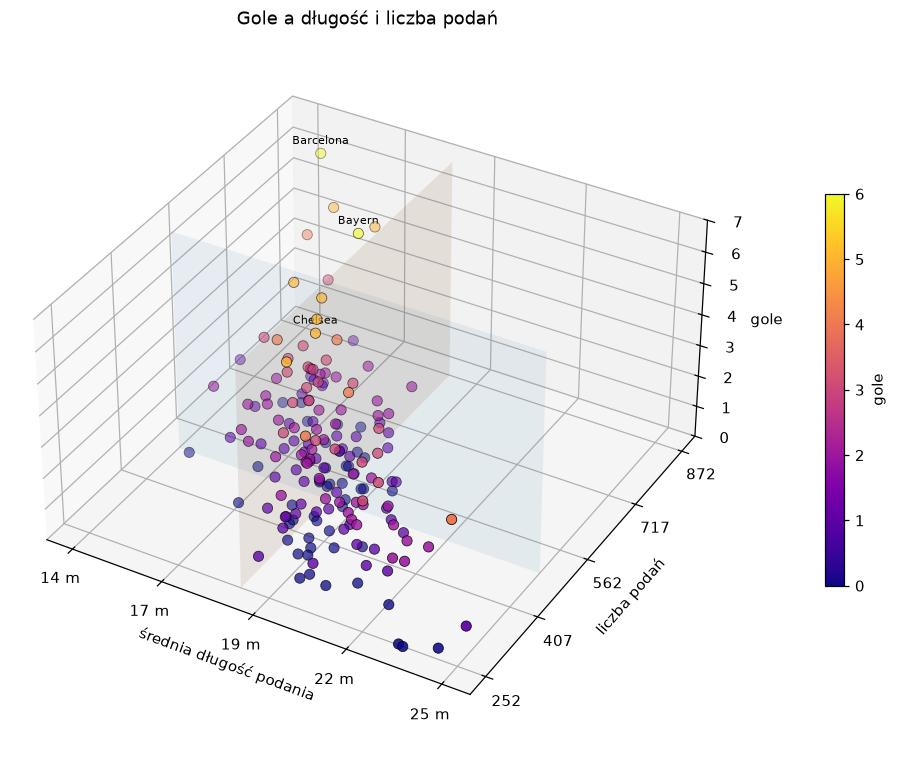

In [4]:
# wykres 3D: długość podania (X) × liczba podań (Y) × gole (Z)
# osie X/Y znormalizowane do 0–1, ale etykiety w metrach i liczbie podań
x = t["dlugosc"].to_numpy()
y = t["podania"].to_numpy()
z = t["gole"].to_numpy().astype(float)

x_n = (x - x.min()) / (x.max() - x.min())
y_n = (y - y.min()) / (y.max() - y.min())

fig = plt.figure(figsize=(9.5, 7))
ax = fig.add_subplot(projection="3d")
punkty = ax.scatter(x_n, y_n, z, c=z, cmap="plasma", s=45,
                    edgecolors="black", linewidths=0.5, depthshade=True)

# ściany w miejscu średnich = cztery ćwiartki
for wartosc, os_ in [(x.mean(), "x"), (y.mean(), "y")]:
    wys = np.array([[0, 0], [z.max() + 1, z.max() + 1]])
    if os_ == "x":
        ax.plot_surface(np.full((2, 2), (wartosc - x.min()) / (x.max() - x.min())),
                        np.array([[0, 1], [0, 1]]), wys, alpha=0.10, color="tab:orange")
    else:
        ax.plot_surface(np.array([[0, 1], [0, 1]]),
                        np.full((2, 2), (wartosc - y.min()) / (y.max() - y.min())), wys,
                        alpha=0.08, color="tab:blue")

# podpisy trzech najskuteczniejszych drużyn
for _, r in t.nlargest(3, "gole").iterrows():
    xn = (r["dlugosc"] - x.min()) / (x.max() - x.min())
    yn = (r["podania"] - y.min()) / (y.max() - y.min())
    ax.text(xn, yn, r["gole"] + 0.3, r["team_name"], fontsize=7, ha="center")

pozycje = np.linspace(0, 1, 5)
ax.set_xticks(pozycje)
ax.set_xticklabels([f"{x.min() + p * (x.max() - x.min()):.0f} m" for p in pozycje])
ax.set_yticks(pozycje)
ax.set_yticklabels([f"{y.min() + p * (y.max() - y.min()):.0f}" for p in pozycje])

ax.set_xlabel("średnia długość podania")
ax.set_ylabel("liczba podań")
ax.set_zlabel("gole")
ax.set_zlim(0, z.max() + 1)
ax.view_init(elev=35, azim=-60)
ax.set_box_aspect((1, 1, 0.55))
ax.set_title("Gole a długość i liczba podań")
fig.colorbar(punkty, shrink=0.55, pad=0.1, label="gole")

plt.tight_layout()
plt.savefig(FIG / "podania_3d_gole.png", dpi=130)
plt.show()


=== cztery ćwiartki ===
               n  gole  punkty  wygrane
duzo krotkie                           
dużo długie   16  1.06    1.00     0.19
     krótkie  78  1.83    1.55     0.41
mało długie   69  1.36    1.22     0.32
     krótkie  21  1.43    1.29     0.33

=== krótkie vs długie (bez liczby podań) ===
          n  podania  dlugosc  gole  punkty  wygrane
krotkie                                             
długie   85   415.16    20.20  1.31    1.18     0.29
krótkie  99   569.92    17.05  1.75    1.49     0.39

=== korelacje (Spearman) ===
  podania    <-> gole       +0.124
  dlugosc    <-> gole       -0.135
  dlugosc    <-> podania    -0.735
  sila       <-> gole       +0.072


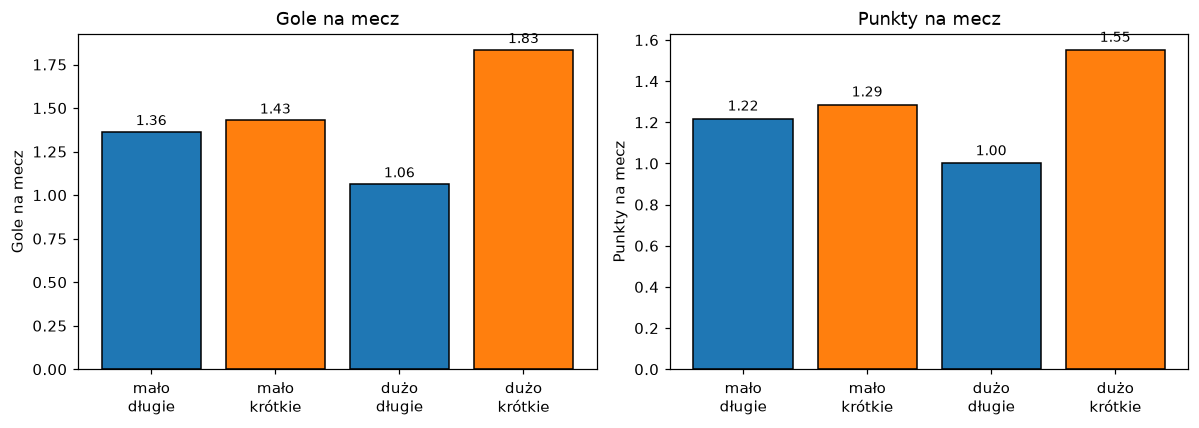

In [5]:
# podział na ćwiartki (długość × liczba podań) i porównanie grup
t["krotkie"] = np.where(t["dlugosc"] < t["dlugosc"].mean(), "krótkie", "długie")
t["duzo"] = np.where(t["podania"] >= t["podania"].mean(), "dużo", "mało")

print("=== cztery ćwiartki ===")
print(t.groupby(["duzo", "krotkie"]).agg(
    n=("gole", "size"), gole=("gole", "mean"),
    punkty=("punkty", "mean"), wygrane=("wygrana", "mean")).round(2).to_string())
print()

print("=== krótkie vs długie (bez liczby podań) ===")
print(t.groupby("krotkie").agg(
    n=("gole", "size"), podania=("podania", "mean"), dlugosc=("dlugosc", "mean"),
    gole=("gole", "mean"), punkty=("punkty", "mean"), wygrane=("wygrana", "mean")).round(2).to_string())
print()

print("=== korelacje (Spearman) ===")
for a, b in [("podania", "gole"), ("dlugosc", "gole"), ("dlugosc", "podania"), ("sila", "gole")]:
    print(f"  {a:<10} <-> {b:<10} {t[a].corr(t[b], method='spearman'):+.3f}")

# wykres: gole i punkty w czterech ćwiartkach
nazwy = ["mało\ndługie", "mało\nkrótkie", "dużo\ndługie", "dużo\nkrótkie"]
gole_cw = [t[(t["duzo"] == d) & (t["krotkie"] == k)]["gole"].mean() for d in ("mało", "dużo") for k in ("długie", "krótkie")]
punkty_cw = [t[(t["duzo"] == d) & (t["krotkie"] == k)]["punkty"].mean() for d in ("mało", "dużo") for k in ("długie", "krótkie")]

fig, osie = plt.subplots(1, 2, figsize=(11, 4))
for ax, wartosci, tytul in [(osie[0], gole_cw, "Gole na mecz"), (osie[1], punkty_cw, "Punkty na mecz")]:
    ax.bar(nazwy, wartosci, color=["tab:blue", "tab:orange", "tab:blue", "tab:orange"], edgecolor="black")
    for i, v in enumerate(wartosci):
        ax.text(i, v + 0.04, f"{v:.2f}", ha="center", fontsize=9)
    ax.set_title(tytul)
    ax.set_ylabel(tytul)
plt.tight_layout()
plt.savefig(FIG / "podania_cwiartki.png", dpi=130)
plt.show()


In [6]:
# testy: interakcja (krótko × często), kontrola siły, porównanie w obrębie meczu
from scipy.stats import t as rozklad_t, binomtest


def z(x):
    return (x - x.mean()) / x.std()


def regresja(cel, kolumny):
    """OLS ze standaryzacją: współczynniki, p-wartości, R2."""
    X = np.column_stack([np.ones(len(t))] + [z(t[k]).to_numpy() for k in kolumny])
    y = t[cel].to_numpy()
    b, *_ = np.linalg.lstsq(X, y, rcond=None)
    reszty = y - X @ b
    dof = len(y) - X.shape[1]
    se = np.sqrt(np.diag(np.linalg.inv(X.T @ X)) * (reszty ** 2).sum() / dof)
    p = 2 * (1 - rozklad_t.cdf(abs(b / se), dof))
    r2 = 1 - (reszty ** 2).sum() / ((y - y.mean()) ** 2).sum()
    return b, p, r2


t["interakcja"] = z(t["podania"]) * z(t["dlugosc"])

print("=== modele goli (standaryzowane) ===")
for nazwa, kolumny in [
    ("podania + długość", ["podania", "dlugosc"]),
    ("+ siła", ["podania", "dlugosc", "sila"]),
    ("+ interakcja", ["podania", "dlugosc", "sila", "interakcja"]),
]:
    b, p, r2 = regresja("gole", kolumny)
    opis = "  ".join(f"{k} {bi:+.3f} (p={pi:.3f})" for k, bi, pi in zip(kolumny, b[1:], p[1:]))
    print(f"  {nazwa:<20} R2={r2:.3f} | {opis}")
print()

# porównanie dwóch drużyn w tym samym meczu
pary = []
for _, m in t.groupby("match_id"):
    if len(m) != 2:
        continue
    m = m.sort_values("podania", ascending=False)
    a, b = m.iloc[0], m.iloc[1]
    pary.append(dict(
        gole_wiecej=a["gole"], gole_mniej=b["gole"],
        sila_wiecej=a["sila"],
        wiecej_krotsze=a["dlugosc"] < b["dlugosc"],
    ))
pary = pd.DataFrame(pary)

krotkie = pary[pary["wiecej_krotsze"]]
dlugie = pary[~pary["wiecej_krotsze"]]

print("=== mecz w meczu: drużyna z większą liczbą podań ===")
print(f"  ma też krótsze podania (n={len(krotkie)}): gole {krotkie['gole_wiecej'].mean():.2f} vs {krotkie['gole_mniej'].mean():.2f}")
print(f"  ma dłuższe podania   (n={len(dlugie)}): gole {dlugie['gole_wiecej'].mean():.2f} vs {dlugie['gole_mniej'].mean():.2f}")
print(f"  średnia różnica Elo w grupie 'więcej+krócej': {krotkie['sila_wiecej'].mean():+.0f}")

# test znaków: czy 'więcej+krócej' częściej wygrywa niż przegrywa
wygrane = int((krotkie["gole_wiecej"] > krotkie["gole_mniej"]).sum())
przegrane = int((krotkie["gole_wiecej"] < krotkie["gole_mniej"]).sum())
print(f"  wygrane/przegrane: {wygrane}/{przegrane}  p = {binomtest(wygrane, wygrane + przegrane).pvalue:.3f}")


=== modele goli (standaryzowane) ===
  podania + długość    R2=0.055 | podania +0.365 (p=0.014)  dlugosc +0.067 (p=0.647)
  + siła               R2=0.057 | podania +0.349 (p=0.020)  dlugosc +0.058 (p=0.694)  sila +0.073 (p=0.464)
  + interakcja         R2=0.084 | podania +0.252 (p=0.102)  dlugosc -0.071 (p=0.650)  sila +0.074 (p=0.454)  interakcja -0.239 (p=0.023)

=== mecz w meczu: drużyna z większą liczbą podań ===
  ma też krótsze podania (n=74): gole 1.76 vs 1.28
  ma dłuższe podania   (n=18): gole 1.56 vs 1.72
  średnia różnica Elo w grupie 'więcej+krócej': +1
  wygrane/przegrane: 31/22  p = 0.272


# Wnioski


**Ćwiartki** (podział na średniej długości i średniej liczby podań):

- „dużo + krótko" — **1,83 gola** i 41% wygranych (najlepszy układ),
- „dużo + długo" — **1,06 gola** i 19% wygranych (najgorszy układ).

Czyli sama duża liczba podań nie pomaga — przy długich podaniach wypada gorzej niż drużyny
podające mało. Dopiero **krótko i często** daje przewagę.

**Interakcja** (podania × długość) w modelu goli: **−0,196, p = 0,023** — efekt liczby podań
jest większy, gdy podania są krótsze. Model z interakcją wyjaśnia ~50% więcej wariancji niż
sam licznik podań.

**Mecz w meczu**: drużyna z większą liczbą podań, gdy ma też krótsze — 1,76 vs 1,28 gola.
Gdy ma więcej podań, ale dłuższych — 1,56 vs 1,72 (strzela *mniej* niż rywal).

**Kontrola siły (Elo)**: różnica Elo przed meczem jest nieistotna (p ≈ 0,46), a interakcja
zostaje na −0,196 przy p = 0,023. Ale Elo przy 92 meczach jest zgrubne — większość drużyn ma
1500, bo zagrały raz lub dwa razy.

## Werdykt

Hipoteza się wyłania i ma istotne wsparcie w interakcji. Czego nie można twierdzić:
że to przyczynowe, i że siła drużyny jest dobrze skontrolowana.

## Ograniczenia

- Obserwacje nie są niezależne — wynik jednej drużyny jest lustrem drugiej.
- Elo z 92 meczów jest słabym przybliżeniem jakości drużyny.
- Brak xG: gole są rzadkie, pojedyncze wyniki 6:1 ciągną średnie.
- Mieszane ligi i poziomy — porównywanie średnich długości między różnymi ligami ma ograniczony sens.
